# Telco Customer Churn — Exploratory Data Analysis

**Goal:** understand who churns and why, before building any model.

The dataset holds ~7,000 telecom customers with their contract, services, billing,
and demographics, plus whether they left (`Churn`). Churn is expensive: keeping an
existing customer costs far less than acquiring a new one, so knowing which
customers are at risk (and which levers matter) has direct business value.

This notebook reuses the cleaning logic from `churn.data` and the plotting helpers
from `churn.eda`, so the charts here are reproducible and identical to the ones
saved under `reports/figures/`.

In [1]:
import pandas as pd

from churn.config import load_config
from churn.data import load_raw_data, clean_data, summarize
from churn import eda

# Render figures inline at a readable size.
%matplotlib inline
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

config = load_config()
TARGET = config.data.target_column
print(f"Target column: {TARGET}")

Target column: Churn


## 1. Load the raw data

Start with the file exactly as downloaded, so we can see the problems before fixing them.

In [2]:
raw = load_raw_data(config)
print(f"Shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Shape: 7,043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.dtypes.to_frame("dtype")

,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


## 2. The `TotalCharges` trap

`TotalCharges` looks numeric but pandas reads it as `object` (text). The reason is
subtle: a handful of rows hold a blank string instead of a number. These are
brand-new customers whose `tenure` is 0 — they simply have not been billed yet.

This matters because a naive `astype(float)` would crash, and blindly dropping the
rows would throw away real customers. We fill them with `0.0`, which is the factual
value rather than a guess.

In [4]:
blank_total = pd.to_numeric(raw["TotalCharges"], errors="coerce").isna()
print(f"Rows with non-numeric TotalCharges: {blank_total.sum()}")
raw.loc[blank_total, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Rows with non-numeric TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Every one of them has `tenure == 0`, which confirms the interpretation. None of them churned.

In [5]:
df = clean_data(raw, config)
print(summarize(df, config))

Cleaned dataset summary
Rows:    7,043
Columns: 20
Missing values: 0

Churn rate: 26.54% (1,869 of 7,043 customers)
Class balance: 5,174 retained / 1,869 churned

Numeric features (4): SeniorCitizen, tenure, MonthlyCharges, TotalCharges
Categorical features (15): gender, Partner, Dependents, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod


## 3. Class balance

About 1 customer in 4 churned. That is imbalanced enough to matter: a model that
predicts "nobody churns" would score ~73% accuracy while being completely useless.
This is why we will evaluate with ROC-AUC and PR-AUC rather than accuracy, and why
we tune the decision threshold later.

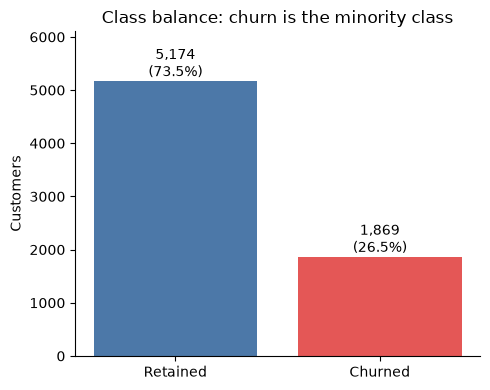

In [6]:
fig = eda.plot_class_balance(df, TARGET)

## 4. Tenure is the strongest single signal

Churn is heavily front-loaded. New customers leave at a dramatically higher rate
than established ones, and the rate decays steadily with every month retained.

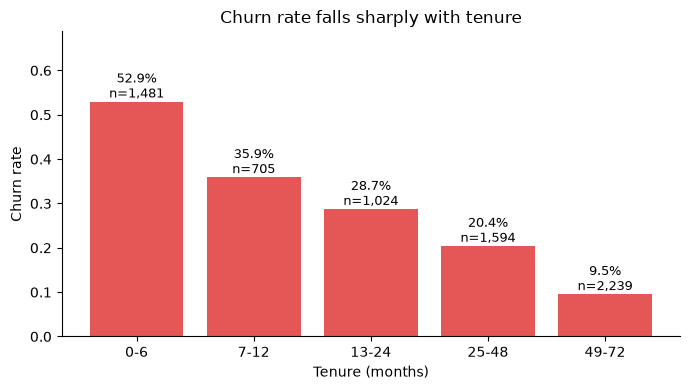

In [7]:
fig = eda.plot_churn_by_tenure(df, TARGET)

In [8]:
print("Median tenure (months):")
print(df.groupby(TARGET)["tenure"].median().rename({0: "Retained", 1: "Churned"}))

Median tenure (months):
Churn
Retained    38.0
Churned     10.0
Name: tenure, dtype: float64


## 5. Contract type: the biggest business lever

Contract length separates customers more cleanly than anything else in the dataset.
Month-to-month customers churn at many times the rate of customers on a two-year deal.

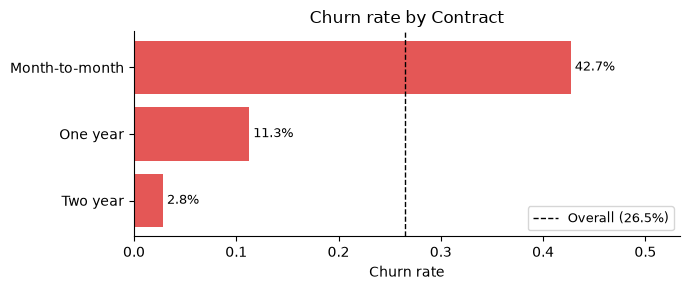

In [9]:
fig = eda.plot_churn_rate_by_column(df, "Contract", TARGET)

In [10]:
(
    eda.churn_rate_by(df, "Contract", TARGET)
    .mul(100)
    .round(2)
    .to_frame("churn_rate_%")
)

,churn_rate_%
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


## 6. Churn across the other categories

Scanning many categorical features at once shows which ones actually separate
churners. The dashed line is the overall churn rate, so bars far from it carry signal.

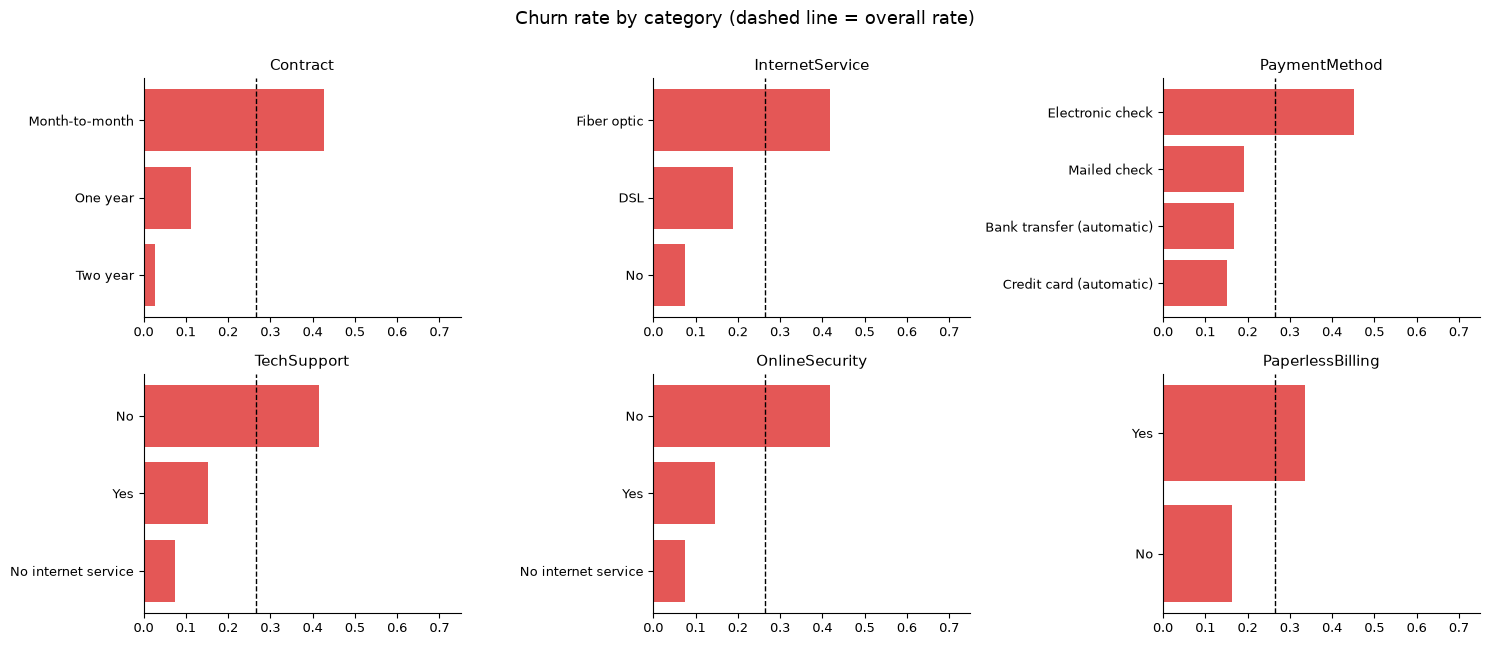

In [11]:
grid_columns = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling",
]
fig = eda.plot_categorical_churn_grid(df, grid_columns, TARGET)

Two patterns stand out:

- **Fiber optic** customers churn far more than DSL or no-internet customers, despite
  fiber being the premium product. Worth flagging to the business as a service-quality
  or price-perception question.
- Customers **without** add-ons like `TechSupport` or `OnlineSecurity` churn more,
  suggesting these services increase stickiness.
- **Electronic check** payers churn notably more than customers on automatic payment methods.

## 7. Numeric feature distributions

Comparing the shape of each numeric feature between churners and non-churners.

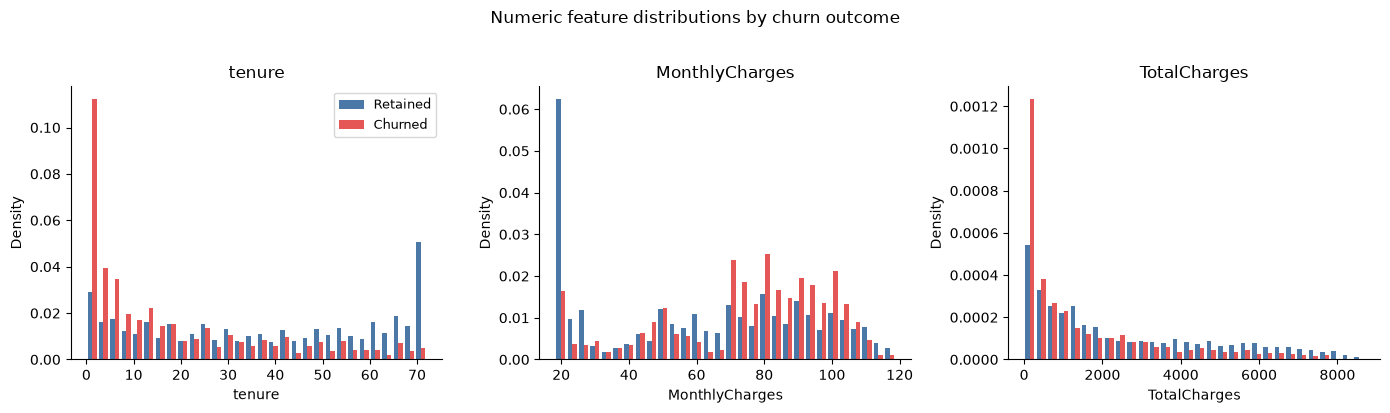

In [12]:
fig = eda.plot_numeric_distributions(df, TARGET)

In [13]:
df.groupby(TARGET)[["tenure", "MonthlyCharges", "TotalCharges"]].describe().T.round(2)

Churn                       0        1
tenure         count  5174.00  1869.00
               mean     37.57    17.98
               std      24.11    19.53
               min       0.00     1.00
               25%      15.00     2.00
               50%      38.00    10.00
               75%      61.00    29.00
               max      72.00    72.00
MonthlyCharges count  5174.00  1869.00
               mean     61.27    74.44
               std      31.09    24.67
               min      18.25    18.85
               25%      25.10    56.15
               50%      64.43    79.65
               75%      88.40    94.20
               max     118.75   118.35
TotalCharges   count  5174.00  1869.00
               mean   2549.91  1531.80
               std    2329.95  1890.82
               min       0.00    18.85
               25%     572.90   134.50
               50%    1679.52   703.55
               75%    4262.85  2331.30
               max    8672.45  8684.80

Churners cluster at low tenure and *high* monthly charges. `TotalCharges` is low for
churners mostly because it is roughly `tenure * MonthlyCharges` — a short-lived
customer cannot accumulate a large total. That makes `TotalCharges` partly redundant
with tenure, which the correlation matrix confirms.

## 8. Correlations

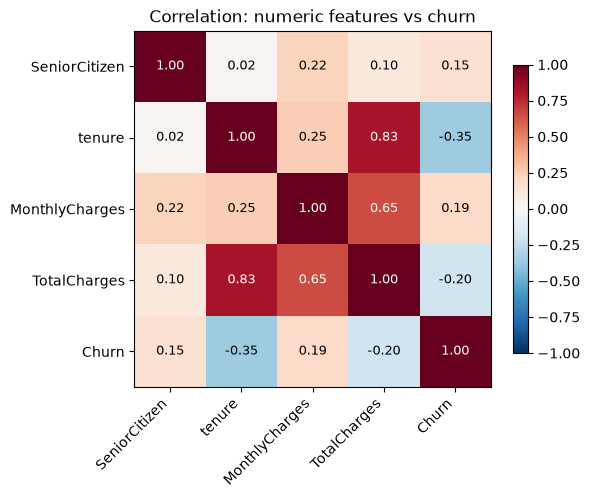

In [14]:
fig = eda.plot_correlation_heatmap(df, TARGET)

`tenure` has the strongest (negative) correlation with churn. `MonthlyCharges` is
positively correlated. Note the strong `tenure`–`TotalCharges` correlation, which is
mechanical rather than informative — tree models handle this fine, and for the linear
baseline we scale features and rely on regularisation.

## 9. Headline numbers

In [15]:
insights = eda.compute_insights(df, TARGET)

print(f"Customers analysed: {insights['n_customers']:,}")
print(f"Overall churn rate: {insights['overall_churn_rate']:.2%}\n")

print("Churn rate by contract:")
for level, rate in insights["contract_churn_rates"].items():
    print(f"  {level:<16} {rate:.2%}")

print("\nChurn rate by tenure bucket (months):")
for level, rate in insights["tenure_churn_rates"].items():
    print(f"  {level:<16} {rate:.2%}")

print("\nCorrelation with churn:")
for name, value in insights["corr_with_churn"].items():
    print(f"  {name:<16} {value:+.3f}")

Customers analysed: 7,043
Overall churn rate: 26.54%

Churn rate by contract:
  Month-to-month   42.71%
  One year         11.27%
  Two year         2.83%

Churn rate by tenure bucket (months):
  0-6              52.94%
  7-12             35.89%
  13-24            28.71%
  25-48            20.39%
  49-72            9.51%

Correlation with churn:
  tenure           -0.352
  MonthlyCharges   +0.193
  TotalCharges     -0.198


## Findings and what they mean for modeling

**1. Churn is front-loaded in the customer lifecycle.** Customers in their first six
months churn at ~53%, falling to ~10% past four years. `tenure` is the single most
predictive feature (correlation −0.35). *Implication:* retention effort is most
valuable early, and tenure must be in the model.

**2. Contract length is the clearest lever.** Month-to-month customers churn at ~43%
versus ~3% on two-year contracts — a 15x gap. *Implication:* a concrete business action
falls out of this analysis (incentivise longer contracts), and `Contract` will likely
dominate feature importance.

**3. Fiber optic customers churn the most (~42%).** The premium product has the worst
retention, roughly double DSL. *Implication:* worth surfacing to the business as a
possible price or service-quality issue, not just a modeling input.

**4. Higher monthly charges go with churn, but total charges do not.** Churners pay more
per month (~\$74 vs ~\$61) yet have lower lifetime totals because they leave early.
*Implication:* price sensitivity is real, and `TotalCharges` is largely a proxy for
tenure — expect it to add little beyond it.

**5. Missing add-on services signal risk.** Customers without `TechSupport` or
`OnlineSecurity` churn well above average. *Implication:* bundling may improve
stickiness, and these flags are useful features.

**6. The classes are imbalanced (26.5% positive).** *Implication:* accuracy is a
misleading metric here. We will use ROC-AUC and PR-AUC for model selection, apply
class weighting during training, and tune the decision threshold to reflect the real
cost of missing a churner.

**Next:** build a leakage-free preprocessing pipeline (`churn.features`), then train and
compare models (`churn.train`).